# Follow-Target Test Set CCA

Evaluate a follow-target policy on **all test set trajectories**, run rollouts,
and perform Canonical Correlation Analysis (CCA) comparing rollout joint angles
to encoder-decoder reference joint angles from the HDF5 dataset.

Builds on `follow_target_test_set_rollout.ipynb` (single-clip evaluation) by
looping over all valid test clips and computing per-clip CCA correlations.

## Imports & Setup

In [16]:
%load_ext autoreload
%autoreload 2

import functools
import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

from pathlib import Path

import h5py
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import orbax.checkpoint as ocp
from ml_collections import ConfigDict
from mujoco import mjx
from omegaconf import OmegaConf
from scipy.stats import pearsonr
from sklearn.cross_decomposition import CCA

from brax.training.agents.ppo import networks as ppo_networks
from brax.training.acme import running_statistics, specs

from scamper.agent import checkpointing
from scamper.agent.task_transfer.follow_target.checkpoint_utils import (
    load_task_transfer_metadata,
    _create_abstract_prior_policy,
    _STEP_PREFIX,
    make_decoder_inference_fn,
    make_prior_inference_fn,
    load_task_transfer_brax_params,
)
from scamper.agent.task_transfer.follow_target.train import (
    extract_skull_trajectories,
)
from scamper.agent.task_transfer.follow_target.wrappers import (
    DecoderHighLevelWrapper,
    PriorDecoderHighLevelWrapper,
    _flatten_obs_for_policy,
)
from scamper.analysis.utils import save_to_h5py
from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import follow_target

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

In [17]:
# ============ CHECKPOINT ============
# Path to the follow_target task transfer checkpoint directory
FOLLOW_TARGET_CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/follow_target_checkpoints/260215_155430_972866"

# Checkpoint step to load (None = latest)
CHECKPOINT_STEP = 123

# Path prefix replacement for checkpoints saved on a different machine.
# Set both to None to skip path fixing.
OLD_PATH_PREFIX = "/tmp/track-mjx"  # e.g., "/tmp/scamper"
NEW_PATH_PREFIX = "/home/mila/a/aidan.sirbu/SCAMPER"  # e.g., "/home/user/scamper"

# ============ ENVIRONMENT OVERRIDES ============
# MuJoCo backend: "jax" or "warp" (None = use checkpoint default)
MUJOCO_IMPL = "warp"

# Walker XML variant (None = use checkpoint default)
WALKER_XML = "rodent_no_tail_collisions.xml"

# ============ ROLLOUT SETTINGS ============
DETERMINISTIC = True  # Use mean action (no sampling)

# ============ SAVE / CCA SETTINGS ============
SAVE_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123_latents.h5"  # Set to save rollouts, e.g. "./test_set_rollouts.h5"
N_CCA_COMPONENTS = 10  # Number of CCA components to compute

## Load Frozen Networks from Task Transfer Checkpoint

In [18]:
# 1. Load metadata (JSON only, lightweight)
metadata = load_task_transfer_metadata(FOLLOW_TARGET_CHECKPOINT_PATH, CHECKPOINT_STEP)
config = metadata["config"]
step = metadata["step"]
ckpt_cfg = config["checkpoint_config"]
ckpt_cfg_omega = OmegaConf.create(ckpt_cfg)

print(f"Loaded metadata from step {step}")
print(f"Training mode: {config.get('mode', 'unknown')}")
print(f"Latent size: {ckpt_cfg['network_config']['intention_size']}")
print(f"Action size: {ckpt_cfg['network_config']['action_size']}")

# 2. Fix paths if needed
OmegaConf.set_struct(ckpt_cfg_omega, False)

if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:

    def fix_path(p):
        if p and p.startswith(OLD_PATH_PREFIX):
            return p.replace(OLD_PATH_PREFIX, NEW_PATH_PREFIX, 1)
        return p

    for key in ["walker_xml_path", "arena_xml_path", "reference_data_path"]:
        OmegaConf.update(
            ckpt_cfg_omega,
            f"env_config.{key}",
            fix_path(ckpt_cfg_omega.env_config[key]),
        )

# Auto-fix XML paths if they don't exist on disk
_xml_lookup = {
    "rodent_full_collisions.xml": str(rodent_consts.RODENT_FULL_COLLISION_XML),
    "rodent_no_tail_collisions.xml": str(rodent_consts.RODENT_NO_TAIL_COLLISION_XML),
    "rodent_box_feet.xml": str(rodent_consts.RODENT_BOX_FEET_PATH),
    "rodent.xml": str(rodent_consts.RODENT_XML_PATH),
    "arena.xml": str(rodent_consts.ARENA_XML_PATH),
}

for key in ["walker_xml_path", "arena_xml_path"]:
    current = ckpt_cfg_omega.env_config[key]
    if not Path(current).exists():
        filename = Path(current).name
        fallback = _xml_lookup.get(filename)
        if fallback is not None:
            OmegaConf.update(ckpt_cfg_omega, f"env_config.{key}", fallback)
            print(f"Fixed {key}: {filename} -> {fallback}")
        else:
            print(f"Warning: {key} not found and no fallback for '{filename}'")

# 3. Apply environment overrides from Configuration cell
if MUJOCO_IMPL is not None:
    OmegaConf.update(ckpt_cfg_omega, "env_config.mujoco_impl", MUJOCO_IMPL)

if WALKER_XML is not None:
    resolved = _xml_lookup.get(WALKER_XML)
    if resolved is not None:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", resolved)
    else:
        OmegaConf.update(ckpt_cfg_omega, "env_config.walker_xml_path", WALKER_XML)

print(f"\nPaths:")
print(f"  walker_xml: {ckpt_cfg_omega.env_config.walker_xml_path}")
print(f"  arena_xml: {ckpt_cfg_omega.env_config.arena_xml_path}")
print(f"  reference_data: {ckpt_cfg_omega.env_config.reference_data_path}")
print(f"  mujoco_impl: {ckpt_cfg_omega.env_config.mujoco_impl}")

# 4. Create abstract pytree structure for restoring frozen networks
abstract_policy = _create_abstract_prior_policy(ckpt_cfg_omega)
normalizer_state, combined_params = abstract_policy

abstract_frozen_networks = {
    "encoder_params": combined_params["params"]["encoder"],
    "prior_params": combined_params["params"]["prior"],
    "decoder_params": combined_params["params"]["decoder"],
    "imitation_normalizer": normalizer_state,
}

# 5. Restore frozen networks from task transfer checkpoint
mgr_options = ocp.CheckpointManagerOptions(create=False, step_prefix=_STEP_PREFIX)
with ocp.CheckpointManager(FOLLOW_TARGET_CHECKPOINT_PATH, options=mgr_options) as mgr:
    restored = mgr.restore(
        step,
        args=ocp.args.Composite(
            frozen_networks=ocp.args.StandardRestore(abstract_frozen_networks),
        ),
    )

frozen = restored["frozen_networks"]
encoder_params = frozen["encoder_params"]
decoder_params = frozen["decoder_params"]
imitation_normalizer = frozen["imitation_normalizer"]

encoder_count = sum(p.size for p in jax.tree_util.tree_leaves(encoder_params))
decoder_count = sum(p.size for p in jax.tree_util.tree_leaves(decoder_params))
print(f"\nFrozen networks loaded successfully")
print(f"  Encoder parameters: {encoder_count:,}")
print(f"  Decoder parameters: {decoder_count:,}")

Loaded metadata from step 123
Training mode: decoder_only
Latent size: 16
Action size: 38
Fixed walker_xml_path: rodent.xml -> /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent.xml
Fixed arena_xml_path: arena.xml -> /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml

Paths:
  walker_xml: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/rodent_no_tail_collisions.xml
  arena_xml: /home/mila/a/aidan.sirbu/vnl-playground/vnl_playground/tasks/rodent/xmls/arena.xml
  reference_data: /home/mila/a/aidan.sirbu/SCAMPER/data/rodent/rodent_reference_clips.h5
  mujoco_impl: warp

Frozen networks loaded successfully
  Encoder parameters: 4,501,536
  Decoder parameters: 1,919,564


## Load Dataset & Reconstruct Test Split

In [19]:
# Read dataset config from checkpoint
# dataset_path = config["env"]["dataset_path"]
dataset_path = "/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5"
dataset_key = config["env"].get("dataset_key", "encoder_decoder")
train_subset_ratio = config["env"].get("train_subset_ratio", 0.8)
seed = config["train"]["seed"]

# Fix dataset_path prefix if needed
if OLD_PATH_PREFIX is not None and NEW_PATH_PREFIX is not None:
    dataset_path = fix_path(dataset_path)

print(f"Dataset path: {dataset_path}")
print(f"Dataset key: {dataset_key}")
print(f"Train subset ratio: {train_subset_ratio}")
print(f"Seed: {seed}")

# Create temporary FollowTarget env for MuJoCo model (needed for FK)
ft_env_cfg = follow_target.default_config()
ckpt_cfg_dict = OmegaConf.to_container(ckpt_cfg_omega, resolve=True)
ft_env_cfg.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
if MUJOCO_IMPL is not None:
    ft_env_cfg.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    _ft_xml_lookup = {
        "rodent_full_collisions.xml": rodent_consts.RODENT_FULL_COLLISION_XML,
        "rodent_no_tail_collisions.xml": rodent_consts.RODENT_NO_TAIL_COLLISION_XML,
        "rodent_box_feet.xml": rodent_consts.RODENT_BOX_FEET_PATH,
        "rodent.xml": rodent_consts.RODENT_XML_PATH,
        "arena.xml": rodent_consts.ARENA_XML_PATH,
    }
    ft_env_cfg.walker_xml_path = _ft_xml_lookup.get(WALKER_XML, WALKER_XML)

_fk_env = follow_target.FollowTarget(config=ft_env_cfg)
mj_model = _fk_env.mj_model

# Extract skull trajectories via FK
print(f"\nExtracting skull trajectories (this may take a minute)...")
skull_trajs, all_qpos = extract_skull_trajectories(dataset_path, dataset_key, mj_model)

num_trajs, traj_len, _ = skull_trajs.shape
print(f"Loaded {num_trajs} trajectories of length {traj_len}")
print(f"  skull_trajs shape: {skull_trajs.shape}")
print(f"  all_qpos shape: {all_qpos.shape}")

# Load reference latents from the dataset (if available)
latents_key = f"{dataset_key}_latents"
with h5py.File(dataset_path, "r") as f:
    if latents_key in f:
        all_latents = f[latents_key][:]
        print(f"  all_latents shape: {all_latents.shape}")
    else:
        all_latents = None
        print(f"  Warning: '{latents_key}' not found in dataset, skipping latents")

# Reconstruct train/test split (same logic as train.py)
num_train = max(1, int(num_trajs * train_subset_ratio))
num_test = num_trajs - num_train

perm = jax.random.permutation(jax.random.PRNGKey(seed), num_trajs)
train_idx = perm[:num_train]
test_idx = perm[num_train:]

print(f"\nTrain/test split (seed={seed}, ratio={train_subset_ratio}):")
print(f"  Train: {num_train} trajectories")
print(f"  Test:  {num_test} trajectories")

Dataset path: /home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout/generation_rollout_goldenrodent_jax_fullclips_latents.h5
Dataset key: encoder_decoder
Train subset ratio: 0.8
Seed: 0

Extracting skull trajectories (this may take a minute)...
Loaded 842 trajectories of length 490
  skull_trajs shape: (842, 490, 3)
  all_qpos shape: (842, 490, 74)
  all_latents shape: (842, 490, 16)

Train/test split (seed=0, ratio=0.8):
  Train: 673 trajectories
  Test:  169 trajectories


## Filter Out Negative-Z Clips

Remove test clips where the skull z position goes negative at any timestep.
These are problematic clips where the rodent passes through the floor.

In [20]:
# skull_trajs already contains FK-computed skull world positions
test_skull_z_min = skull_trajs[test_idx][:, :, 2].min(axis=1)
valid_mask = test_skull_z_min >= 0
filtered_test_idx = test_idx[valid_mask]

num_filtered_out = int(num_test - valid_mask.sum())
print(f"Test clips before filtering: {num_test}")
print(f"Clips with negative skull z (filtered out): {num_filtered_out}")
print(f"Valid test clips remaining: {len(filtered_test_idx)}")

if num_filtered_out > 0:
    invalid_global_idx = test_idx[~valid_mask]
    print(f"Filtered global indices: {np.array(invalid_global_idx)}")

Test clips before filtering: 169
Clips with negative skull z (filtered out): 1
Valid test clips remaining: 168
Filtered global indices: [64]


## Create FollowTarget Environment + Wrapper

In [21]:
task_cfg = config  # full task transfer config from checkpoint metadata
latent_size = ckpt_cfg_dict["network_config"]["intention_size"]
proprio_size = ckpt_cfg_dict["network_config"]["obs_sizes"]["proprioception"]
ft_episode_length = traj_len

# Apply task env settings from checkpoint
ft_env_cfg_rollout = follow_target.default_config()
ft_env_cfg_rollout.ctrl_dt = ckpt_cfg_dict["env_config"]["ctrl_dt"]
ft_env_cfg_rollout.distance_margin = task_cfg["env"]["distance_margin"]
ft_env_cfg_rollout.amp_x = task_cfg["env"]["amp_x"]
ft_env_cfg_rollout.amp_y = task_cfg["env"]["amp_y"]
ft_env_cfg_rollout.amp_z = task_cfg["env"]["amp_z"]
ft_env_cfg_rollout.z_min_offset = task_cfg["env"]["z_min_offset"]
ft_env_cfg_rollout.sigma_smooth = task_cfg["env"]["sigma_smooth"]

# Override episode_length to match dataset trajectory length
ft_env_cfg_rollout.episode_length = ft_episode_length

ft_env_cfg_rollout.reward_terms = {
    "distance_to_target": {
        "weight": task_cfg["env"]["reward_weights"]["distance_to_target"]
    },
}

# Apply same environment overrides
if MUJOCO_IMPL is not None:
    ft_env_cfg_rollout.mujoco_impl = MUJOCO_IMPL
if WALKER_XML is not None:
    ft_env_cfg_rollout.walker_xml_path = _ft_xml_lookup.get(WALKER_XML, WALKER_XML)

ft_base_env = follow_target.FollowTarget(config=ft_env_cfg_rollout)

# --- Wrap with the appropriate wrapper based on training mode ---
training_mode = config.get("mode", "prior_decoder")

ft_decoder_fn = make_decoder_inference_fn(
    decoder_params, imitation_normalizer, ckpt_cfg_dict
)

if training_mode == "prior_decoder":
    ft_prior_fn = make_prior_inference_fn(
        frozen["prior_params"], imitation_normalizer, ckpt_cfg_dict
    )
    ft_env = PriorDecoderHighLevelWrapper(
        ft_base_env,
        ft_prior_fn,
        ft_decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=task_cfg.get("prior_decoder", {}).get(
            "deterministic_prior", True
        ),
        noise_logvar=task_cfg.get("prior_decoder", {}).get("noise_logvar", -2.0),
    )
elif training_mode == "decoder_only":
    ft_env = DecoderHighLevelWrapper(
        ft_base_env,
        ft_decoder_fn,
        latent_size,
        proprio_size,
    )
else:
    raise ValueError(
        f"Unsupported training mode for follow_target rollout: '{training_mode}'. "
        f"Expected 'prior_decoder' or 'decoder_only'."
    )

print(f"FollowTarget wrapped env created (mode: {training_mode})")
print(
    f"  Obs size: {ft_env.observation_size}, Action size (latent): {ft_env.action_size}"
)

FollowTarget wrapped env created (mode: decoder_only)
  Obs size: 334, Action size (latent): 16


## Load Brax PPO Params

In [22]:
normalize_fn = (
    running_statistics.normalize
    if task_cfg["train"].get("normalize_observations", True)
    else lambda x, y: x
)

jit_ft_reset = jax.jit(ft_env.reset)
jit_ft_step = jax.jit(ft_env.step)
ft_start_state = jit_ft_reset(jax.random.PRNGKey(0))

obs_size_ft = ft_start_state.obs.shape[-1]
action_size_ft = ft_env.action_size

ppo_net = ppo_networks.make_ppo_networks(
    obs_size_ft,
    action_size_ft,
    preprocess_observations_fn=normalize_fn,
    policy_hidden_layer_sizes=tuple(task_cfg["network"]["policy_layers"]),
    value_hidden_layer_sizes=tuple(task_cfg["network"]["value_layers"]),
)

# Build abstract pytree for Orbax restoration
key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
abstract_normalizer = running_statistics.init_state(
    specs.Array(ft_start_state.obs.shape[-1:], jnp.dtype("float32"))
)
abstract_policy_params = ppo_net.policy_network.init(key_p)
abstract_value_params = ppo_net.value_network.init(key_v)
abstract_brax_params = (
    abstract_normalizer,
    abstract_policy_params,
    abstract_value_params,
)

brax_params = load_task_transfer_brax_params(
    FOLLOW_TARGET_CHECKPOINT_PATH,
    abstract_brax_params,
    step=step,
)

param_count = sum(p.size for p in jax.tree_util.tree_leaves(brax_params[1]))
print(f"Brax PPO params loaded (policy: {param_count:,} parameters)")

Brax PPO params loaded (policy: 3,325,472 parameters)


## Run Rollouts on All Test Clips

In [8]:
# --- Build deterministic inference function for follow_target policy ---
ft_policy_network = ppo_net.policy_network
ft_action_dist = ppo_net.parametric_action_distribution


def follow_target_policy(params, observations, key_sample):
    del key_sample
    param_subset = (params[0], params[1])
    logits = ft_policy_network.apply(*param_subset, observations)
    return ft_action_dist.mode(logits), {}


# --- Scan-based rollout: compile entire trajectory as one XLA program ---
def _rollout_scan_body(carry, _):
    """Single step for jax.lax.scan: infer action, step env, return qpos + latent."""
    state, rng = carry
    rng, act_rng = jax.random.split(rng)
    param_subset = (brax_params[0], brax_params[1])
    logits = ft_policy_network.apply(*param_subset, state.obs)
    action = ft_action_dist.mode(logits)
    next_state = ft_env.step(state, action)
    # decoder_only: action IS the latent; prior_decoder: combined latent in info
    latent = (
        next_state.info["final_latent"] if "final_latent" in next_state.info else action
    )
    return (next_state, rng), (next_state.data.qpos, latent)


@jax.jit
def rollout_one_clip(state, rng):
    """Run a full trajectory rollout using jax.lax.scan (no Python loop)."""
    init_qpos = state.data.qpos
    (final_state, _), (stepped_qpos, stepped_latents) = jax.lax.scan(
        _rollout_scan_body, (state, rng), None, length=ft_episode_length - 1
    )
    # Prepend initial qpos: (1, 74) + (T-1, 74) -> (T, 74)
    qpos_traj = jnp.concatenate([init_qpos[None], stepped_qpos], axis=0)
    # Prepend zeros for latent at t=0 (no policy call at initial timestep)
    latents_traj = jnp.concatenate(
        [jnp.zeros((1, latent_size)), stepped_latents], axis=0
    )
    return qpos_traj, latents_traj


# --- Run rollouts on all valid test clips ---
num_valid_test = len(filtered_test_idx)
all_rollout_qpos = np.zeros((num_valid_test, ft_episode_length, 74), dtype=np.float32)
all_rollout_latents = np.zeros(
    (num_valid_test, ft_episode_length, latent_size), dtype=np.float32
)

PROGRESS_EVERY = 10

print(
    f"Running rollouts on {num_valid_test} test clips ({ft_episode_length} steps each)..."
)
print("(First clip includes JIT compilation time)")

for i in range(num_valid_test):
    global_idx = int(filtered_test_idx[i])
    skull_traj = skull_trajs[global_idx]  # (T, 3)
    init_qpos_clip = all_qpos[global_idx, 0]  # (74,)

    # Reset environment
    rng = jax.random.PRNGKey(42 + i)
    rng, reset_rng = jax.random.split(rng)
    state = jit_ft_reset(reset_rng)

    # Initialize from HDF5 qpos
    new_qpos = jnp.array(init_qpos_clip)
    new_data = state.data.replace(
        qpos=new_qpos,
        qvel=jnp.zeros_like(state.data.qvel),
    )
    new_data = mjx.forward(ft_base_env.mjx_model, new_data)

    # Inject skull trajectory as the target trajectory
    new_info = {**state.info, "target_trajectory": jnp.array(skull_traj)}

    # Recompute observations with new data and injected trajectory
    new_obs = ft_base_env._get_obs(new_data, new_info)
    flat_obs = _flatten_obs_for_policy(new_obs)
    state = state.replace(data=new_data, obs=flat_obs, info=new_info)

    # Single JIT call for the entire trajectory
    qpos_traj, latents_traj = rollout_one_clip(state, rng)
    all_rollout_qpos[i] = np.array(qpos_traj)
    all_rollout_latents[i] = np.array(latents_traj)

    if (i + 1) % PROGRESS_EVERY == 0 or i == 0 or i == num_valid_test - 1:
        print(f"  [{i + 1}/{num_valid_test}] clip global_idx={global_idx} done")

# Gather reference qpos and latents for valid test clips
all_ref_qpos = np.array(all_qpos[filtered_test_idx])  # (num_valid_test, T, 74)
all_ref_latents = (
    np.array(all_latents[filtered_test_idx]) if all_latents is not None else None
)

print(f"\nRollouts complete")
print(f"  all_rollout_qpos shape: {all_rollout_qpos.shape}")
print(f"  all_rollout_latents shape: {all_rollout_latents.shape}")
print(f"  all_ref_qpos shape: {all_ref_qpos.shape}")
if all_ref_latents is not None:
    print(f"  all_ref_latents shape: {all_ref_latents.shape}")
else:
    print(f"  all_ref_latents: None (dataset had no latents)")

Running rollouts on 168 test clips (490 steps each)...
(First clip includes JIT compilation time)
  [1/168] clip global_idx=99 done
  [10/168] clip global_idx=589 done
  [20/168] clip global_idx=33 done
  [30/168] clip global_idx=357 done
  [40/168] clip global_idx=652 done
  [50/168] clip global_idx=388 done
  [60/168] clip global_idx=444 done
  [70/168] clip global_idx=480 done
  [80/168] clip global_idx=580 done
  [90/168] clip global_idx=432 done
  [100/168] clip global_idx=686 done
  [110/168] clip global_idx=378 done
  [120/168] clip global_idx=222 done
  [130/168] clip global_idx=183 done
  [140/168] clip global_idx=296 done
  [150/168] clip global_idx=284 done
  [160/168] clip global_idx=249 done
  [168/168] clip global_idx=211 done

Rollouts complete
  all_rollout_qpos shape: (168, 490, 74)
  all_rollout_latents shape: (168, 490, 16)
  all_ref_qpos shape: (168, 490, 74)
  all_ref_latents shape: (168, 490, 16)


## Load Previously Saved Rollouts (Optional)

Skip the rollout cells above and load pre-computed rollouts from an H5 file.
Set `LOAD_PATH` below and run this cell instead. The loaded arrays will
overwrite `all_rollout_qpos` and `all_ref_qpos`.

In [ ]:
# Set LOAD_PATH to a previously saved H5 file to skip rollout generation.
# This cell is a no-op if LOAD_PATH is None.
LOAD_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/decoder_only_123.h5"  # e.g. "/home/mila/a/aidan.sirbu/SCAMPER/data/cca/prior_decoder_123.h5"

if LOAD_PATH is not None:
    from scamper.analysis.utils import load_from_h5py

    loaded = load_from_h5py(LOAD_PATH)
    all_rollout_qpos = loaded["rollout_qpos"]
    all_ref_qpos = loaded["reference_qpos"]
    all_rollout_latents = loaded.get("rollout_latents", None)
    all_ref_latents = loaded.get("reference_latents", None)

    print(f"Loaded rollouts from {LOAD_PATH}")
    print(f"  rollout_qpos: {all_rollout_qpos.shape}")
    print(f"  reference_qpos: {all_ref_qpos.shape}")
    if all_rollout_latents is not None:
        print(f"  rollout_latents: {all_rollout_latents.shape}")
    else:
        print(f"  rollout_latents: not present in file")
    if all_ref_latents is not None:
        print(f"  reference_latents: {all_ref_latents.shape}")
    else:
        print(f"  reference_latents: not present in file")
    if "filtered_test_idx" in loaded:
        print(f"  filtered_test_idx: {loaded['filtered_test_idx'].shape}")
else:
    print("LOAD_PATH is None, using rollouts from cells above.")

## Save Rollouts (Optional)

Set `SAVE_PATH` in the configuration cell to save the rollout data.

In [9]:
if SAVE_PATH is not None:
    save_data = {
        "rollout_qpos": all_rollout_qpos,
        "reference_qpos": all_ref_qpos,
        "rollout_latents": all_rollout_latents,
        "filtered_test_idx": np.array(filtered_test_idx),
    }
    if all_ref_latents is not None:
        save_data["reference_latents"] = all_ref_latents

    save_to_h5py(SAVE_PATH, save_data)
    print(f"Saved rollouts to {SAVE_PATH}")
    print(f"  rollout_qpos: {all_rollout_qpos.shape}")
    print(f"  reference_qpos: {all_ref_qpos.shape}")
    print(f"  rollout_latents: {all_rollout_latents.shape}")
    if all_ref_latents is not None:
        print(f"  reference_latents: {all_ref_latents.shape}")
    else:
        print(f"  reference_latents: skipped (not available)")
    print(f"  filtered_test_idx: {np.array(filtered_test_idx).shape}")
else:
    print("SAVE_PATH is None, skipping save. Set it in the configuration cell to save.")

Saved rollouts to /home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123_latents.h5
  rollout_qpos: (168, 490, 74)
  reference_qpos: (168, 490, 74)
  rollout_latents: (168, 490, 16)
  reference_latents: (168, 490, 16)
  filtered_test_idx: (168,)


## Kernel Inception Distance (KID)

Train a VAE on the reference qpos data, extract latent features (mu vectors)
from both reference and rollout datasets, then compute KID using a polynomial
kernel MMD estimator (same methodology as `scamper/scripts/inception_distance.py`).

In [7]:
from scamper.scripts.inception_distance import (
    preprocess_data,
    train_vae,
    extract_features,
    compute_kid,
)

# --- KID hyperparameters (matching inception_distance.py defaults) ---
KID_LATENT_DIM = 64
KID_HIDDEN_LAYERS = [512, 256]
KID_NUM_EPOCHS = 1000
KID_BATCH_SIZE = 128
KID_LEARNING_RATE = 1e-3
KID_WEIGHT_DECAY = 1e-5
KID_GRAD_CLIP_NORM = 1.0
KID_DROPOUT_RATE = 0.1
KID_BETA = 1.0
KID_BETA_WARMUP_EPOCHS = KID_NUM_EPOCHS // 2
KID_SEED = 0
KID_EXCLUDE_XY = True
KID_HANDLE_ROTATION = True

# --- Preprocess ---
ref_data = preprocess_data(all_ref_qpos, KID_EXCLUDE_XY, KID_HANDLE_ROTATION)
rollout_data = preprocess_data(all_rollout_qpos, KID_EXCLUDE_XY, KID_HANDLE_ROTATION)
input_size = int(np.prod(ref_data.shape[1:]))
print(f"Preprocessed shapes: ref={ref_data.shape}, rollout={rollout_data.shape}")
print(f"Flattened input size: {input_size}")

# --- Train VAE on reference (real) data ---
print(
    f"\nTraining VAE (latent_dim={KID_LATENT_DIM}, epochs={KID_NUM_EPOCHS}, seed={KID_SEED})..."
)
trained_params, network_fns, train_metrics = train_vae(
    data=ref_data,
    input_size=input_size,
    latent_dim=KID_LATENT_DIM,
    encoder_hidden_layer_sizes=tuple(KID_HIDDEN_LAYERS),
    decoder_hidden_layer_sizes=None,
    num_epochs=KID_NUM_EPOCHS,
    batch_size=KID_BATCH_SIZE,
    learning_rate=KID_LEARNING_RATE,
    weight_decay=KID_WEIGHT_DECAY,
    grad_clip_norm=KID_GRAD_CLIP_NORM,
    dropout_rate=KID_DROPOUT_RATE,
    use_layer_norm=True,
    target_beta=KID_BETA,
    beta_warmup_epochs=KID_BETA_WARMUP_EPOCHS,
    seed=KID_SEED,
)
print(f"VAE training complete. Final metrics: {train_metrics}")

# --- Extract features ---
_, _, _, encode_fn = network_fns
mu_ref = extract_features(trained_params, encode_fn, ref_data)
mu_rollout = extract_features(trained_params, encode_fn, rollout_data)
print(f"\nFeature shapes: mu_ref={mu_ref.shape}, mu_rollout={mu_rollout.shape}")

# --- Compute KID ---
kid_mean, kid_std = compute_kid(mu_ref, mu_rollout)
print(f"\nKID = {kid_mean:.6f} +/- {kid_std:.6f}")

Preprocessed shapes: ref=(168, 490, 74), rollout=(168, 490, 74)
Flattened input size: 36260

Training VAE (latent_dim=64, epochs=1000, seed=0)...


VAE training (seed=0): 100%|██████████| 1000/1000 [00:14<00:00, 70.99it/s]


VAE training complete. Final metrics: {'beta': 1.0, 'kl_loss': 53.89958572387695, 'recon_loss': 160.23587036132812, 'total_loss': 214.1354522705078}

Feature shapes: mu_ref=(168, 64), mu_rollout=(168, 64)

KID = 0.449952 +/- 0.000000


## Mean Squared Jerk (Joint Angles)

Compute mean squared jerk of the joint angles (qpos indices 7:, excluding root
position and quaternion) for both reference and rollout trajectories.
Jerk is the third finite difference of the joint angle time series.

In [8]:
# Extract joint angles only (indices 7: skip root pos + quaternion)
ref_joints = all_ref_qpos[:, :, 7:]  # (num_clips, T, 67)
rollout_joints = all_rollout_qpos[:, :, 7:]  # (num_clips, T, 67)

# Jerk = third finite difference along the time axis
ref_jerk = np.diff(ref_joints, n=3, axis=1)  # (num_clips, T-3, 67)
rollout_jerk = np.diff(rollout_joints, n=3, axis=1)  # (num_clips, T-3, 67)

# Mean squared jerk: average over time and joints, per clip
ref_msj_per_clip = np.mean(ref_jerk**2, axis=(1, 2))  # (num_clips,)
rollout_msj_per_clip = np.mean(rollout_jerk**2, axis=(1, 2))  # (num_clips,)

# Global mean squared jerk (average across all clips)
ref_msj = np.mean(ref_msj_per_clip)
rollout_msj = np.mean(rollout_msj_per_clip)

print(f"Mean Squared Jerk (joint angles, qpos[7:]):")
print(f"  Reference: {ref_msj:.6f}  (std across clips: {np.std(ref_msj_per_clip):.6f})")
print(
    f"  Rollout:   {rollout_msj:.6f}  (std across clips: {np.std(rollout_msj_per_clip):.6f})"
)
print(f"  Ratio (rollout / reference): {rollout_msj / ref_msj:.4f}")

Mean Squared Jerk (joint angles, qpos[7:]):
  Reference: 0.000098  (std across clips: 0.000087)
  Rollout:   0.000160  (std across clips: 0.000116)
  Ratio (rollout / reference): 1.6402


In [10]:
# Extract joint angles only (indices 7: skip root pos + quaternion)
ref_joints = all_ref_qpos[:, :, 7:]  # (num_clips, T, 67)
rollout_joints = all_rollout_qpos[:, :, 7:]  # (num_clips, T, 67)

# Jerk = third finite difference along the time axis
ref_jerk = np.diff(ref_joints, n=3, axis=1)  # (num_clips, T-3, 67)
rollout_jerk = np.diff(rollout_joints, n=3, axis=1)  # (num_clips, T-3, 67)

# Mean squared jerk: average over time and joints, per clip
ref_msj_per_clip = np.mean(ref_jerk**2, axis=(1, 2))  # (num_clips,)
rollout_msj_per_clip = np.mean(rollout_jerk**2, axis=(1, 2))  # (num_clips,)

# Global mean squared jerk (average across all clips)
ref_msj = np.mean(ref_msj_per_clip)
rollout_msj = np.mean(rollout_msj_per_clip)

print(f"Mean Squared Jerk (joint angles, qpos[7:]):")
print(f"  Reference: {ref_msj:.6f}  (std across clips: {np.std(ref_msj_per_clip):.6f})")
print(
    f"  Rollout:   {rollout_msj:.6f}  (std across clips: {np.std(rollout_msj_per_clip):.6f})"
)
print(f"  Ratio (rollout / reference): {rollout_msj / ref_msj:.4f}")

Mean Squared Jerk (joint angles, qpos[7:]):
  Reference: 0.000098  (std across clips: 0.000087)
  Rollout:   0.000188  (std across clips: 0.000088)
  Ratio (rollout / reference): 1.9279


## PSD Wasserstein Distance (Joint Velocities)

Compute joint velocities (first finite difference of joint angles), estimate
the Power Spectral Density (PSD) of each joint via FFT, average across joints
and clips, then compute the 1D Wasserstein distance between the reference and
rollout mean PSDs.

Prior_decoder

In [11]:
from scipy.stats import wasserstein_distance

# Joint velocities via first finite difference (indices 7: = joint angles only)
ref_vel = np.diff(all_ref_qpos[:, :, 7:], n=1, axis=1)  # (num_clips, T-1, 67)
rollout_vel = np.diff(all_rollout_qpos[:, :, 7:], n=1, axis=1)  # (num_clips, T-1, 67)

num_clips, n_timesteps, n_joints = ref_vel.shape

# PSD via FFT (one-sided, per clip per joint)
# rfft returns N//2+1 complex coefficients; PSD = |X|^2 / N
ref_fft = np.fft.rfft(ref_vel, axis=1)
rollout_fft = np.fft.rfft(rollout_vel, axis=1)

ref_psd = np.abs(ref_fft) ** 2 / n_timesteps  # (num_clips, n_freq, n_joints)
rollout_psd = np.abs(rollout_fft) ** 2 / n_timesteps

# Average PSD across clips and joints -> single 1D spectrum per dataset
ref_mean_psd = ref_psd.mean(axis=(0, 2))  # (n_freq,)
rollout_mean_psd = rollout_psd.mean(axis=(0, 2))  # (n_freq,)

# Normalize PSDs to valid probability distributions for Wasserstein distance
ref_psd_norm = ref_mean_psd / ref_mean_psd.sum()
rollout_psd_norm = rollout_mean_psd / rollout_mean_psd.sum()

# Frequency bins (used as the "locations" for the 1D Wasserstein distance)
freqs = np.arange(len(ref_mean_psd))

w_dist = wasserstein_distance(freqs, freqs, ref_psd_norm, rollout_psd_norm)

print(f"PSD Wasserstein Distance (joint velocities):")
print(f"  Wasserstein distance: {w_dist:.6f}")
print(f"  Number of frequency bins: {len(freqs)}")
print(f"  Reference total PSD power: {ref_mean_psd.sum():.4f}")
print(f"  Rollout total PSD power:   {rollout_mean_psd.sum():.4f}")

PSD Wasserstein Distance (joint velocities):
  Wasserstein distance: 7.475424
  Number of frequency bins: 245
  Reference total PSD power: 0.0268
  Rollout total PSD power:   0.0352


Decoder_only

In [13]:
from scipy.stats import wasserstein_distance

# Joint velocities via first finite difference (indices 7: = joint angles only)
ref_vel = np.diff(all_ref_qpos[:, :, 7:], n=1, axis=1)  # (num_clips, T-1, 67)
rollout_vel = np.diff(all_rollout_qpos[:, :, 7:], n=1, axis=1)  # (num_clips, T-1, 67)

num_clips, n_timesteps, n_joints = ref_vel.shape

# PSD via FFT (one-sided, per clip per joint)
# rfft returns N//2+1 complex coefficients; PSD = |X|^2 / N
ref_fft = np.fft.rfft(ref_vel, axis=1)
rollout_fft = np.fft.rfft(rollout_vel, axis=1)

ref_psd = np.abs(ref_fft) ** 2 / n_timesteps  # (num_clips, n_freq, n_joints)
rollout_psd = np.abs(rollout_fft) ** 2 / n_timesteps

# Average PSD across clips and joints -> single 1D spectrum per dataset
ref_mean_psd = ref_psd.mean(axis=(0, 2))  # (n_freq,)
rollout_mean_psd = rollout_psd.mean(axis=(0, 2))  # (n_freq,)

# Normalize PSDs to valid probability distributions for Wasserstein distance
ref_psd_norm = ref_mean_psd / ref_mean_psd.sum()
rollout_psd_norm = rollout_mean_psd / rollout_mean_psd.sum()

# Frequency bins (used as the "locations" for the 1D Wasserstein distance)
freqs = np.arange(len(ref_mean_psd))

w_dist = wasserstein_distance(freqs, freqs, ref_psd_norm, rollout_psd_norm)

print(f"PSD Wasserstein Distance (joint velocities):")
print(f"  Wasserstein distance: {w_dist:.6f}")
print(f"  Number of frequency bins: {len(freqs)}")
print(f"  Reference total PSD power: {ref_mean_psd.sum():.4f}")
print(f"  Rollout total PSD power:   {rollout_mean_psd.sum():.4f}")

PSD Wasserstein Distance (joint velocities):
  Wasserstein distance: 10.262909
  Number of frequency bins: 245
  Reference total PSD power: 0.0268
  Rollout total PSD power:   0.0259


## Decoder-Only vs Prior-Decoder Comparison

Load saved rollouts for both modes, compute per-clip joint-angle MSE and
per-clip PSD Wasserstein distance (each vs its own reference), then scatter
plot all clips coloured by mode.

Decoder-only:  rollout (168, 490, 74), ref (168, 490, 74)
Prior-decoder: rollout (168, 490, 74), ref (168, 490, 74)

Metric                                 Decoder-Only        Prior-Decoder
------------------------------------------------------------------------
Joint MSE (mean +/- std)       0.034082 +/- 0.020097   0.054755 +/- 0.026262
PSD W-dist (mean +/- std)      15.6892 +/- 13.9467       16.4305 +/- 12.8695


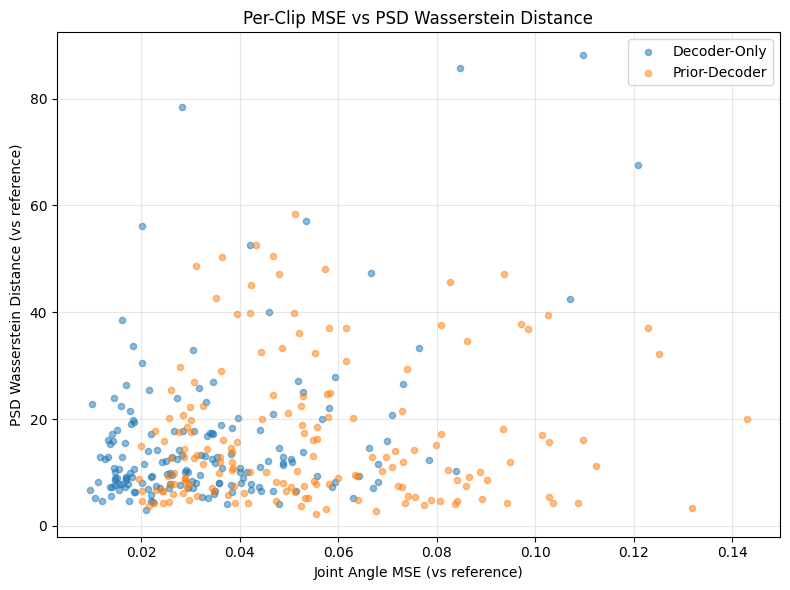

In [3]:
from scamper.analysis.utils import load_from_h5py
from scipy.stats import wasserstein_distance

# ============ PATHS ============
DECODER_ONLY_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/decoder_only_123.h5"
)
PRIOR_DECODER_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123.h5"
)

# ============ LOAD ============
do_data = load_from_h5py(DECODER_ONLY_PATH)
pd_data = load_from_h5py(PRIOR_DECODER_PATH)

do_rollout = do_data["rollout_qpos"]  # (N, T, 74)
do_ref = do_data["reference_qpos"]  # (N, T, 74)
pd_rollout = pd_data["rollout_qpos"]  # (N, T, 74)
pd_ref = pd_data["reference_qpos"]  # (N, T, 74)

print(f"Decoder-only:  rollout {do_rollout.shape}, ref {do_ref.shape}")
print(f"Prior-decoder: rollout {pd_rollout.shape}, ref {pd_ref.shape}")

# ============ PER-CLIP JOINT-ANGLE MSE (qpos[7:]) ============
do_mse = np.mean((do_rollout[:, :, 7:] - do_ref[:, :, 7:]) ** 2, axis=(1, 2))  # (N,)
pd_mse = np.mean((pd_rollout[:, :, 7:] - pd_ref[:, :, 7:]) ** 2, axis=(1, 2))  # (N,)


# ============ PER-CLIP PSD WASSERSTEIN (joint velocities) ============
def per_clip_psd_wasserstein(rollout_qpos, ref_qpos):
    """Compute PSD Wasserstein distance per clip on joint velocities."""
    # Joint velocities
    roll_vel = np.diff(rollout_qpos[:, :, 7:], n=1, axis=1)  # (N, T-1, 67)
    ref_vel = np.diff(ref_qpos[:, :, 7:], n=1, axis=1)
    n_clips, n_t, n_j = roll_vel.shape
    n_freq = n_t // 2 + 1
    freqs = np.arange(n_freq)

    # PSD per clip, averaged over joints
    roll_psd = (np.abs(np.fft.rfft(roll_vel, axis=1)) ** 2 / n_t).mean(
        axis=2
    )  # (N, n_freq)
    ref_psd = (np.abs(np.fft.rfft(ref_vel, axis=1)) ** 2 / n_t).mean(axis=2)

    w_dists = np.empty(n_clips)
    for i in range(n_clips):
        rp = roll_psd[i]
        rr = ref_psd[i]
        # Normalise to distributions
        rp_norm = rp / rp.sum() if rp.sum() > 0 else rp
        rr_norm = rr / rr.sum() if rr.sum() > 0 else rr
        w_dists[i] = wasserstein_distance(freqs, freqs, rp_norm, rr_norm)
    return w_dists


do_wdist = per_clip_psd_wasserstein(do_rollout, do_ref)  # (N,)
pd_wdist = per_clip_psd_wasserstein(pd_rollout, pd_ref)  # (N,)

# ============ SUMMARY ============
print(f"\n{'Metric':<30} {'Decoder-Only':>20} {'Prior-Decoder':>20}")
print("-" * 72)
print(
    f"{'Joint MSE (mean +/- std)':<30} {do_mse.mean():.6f} +/- {do_mse.std():.6f}   {pd_mse.mean():.6f} +/- {pd_mse.std():.6f}"
)
print(
    f"{'PSD W-dist (mean +/- std)':<30} {do_wdist.mean():.4f} +/- {do_wdist.std():.4f}       {pd_wdist.mean():.4f} +/- {pd_wdist.std():.4f}"
)

# ============ SCATTER PLOT ============
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(do_mse, do_wdist, alpha=0.5, s=20, label="Decoder-Only")
ax.scatter(pd_mse, pd_wdist, alpha=0.5, s=20, label="Prior-Decoder")
ax.set_xlabel("Joint Angle MSE (vs reference)")
ax.set_ylabel("PSD Wasserstein Distance (vs reference)")
ax.set_title("Per-Clip MSE vs PSD Wasserstein Distance")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## MSE vs Cross-Correlation Frobenius Norm

For each clip, compute the cross-correlation matrix of joint velocities
(67x67 Pearson correlation across time) for both rollout and reference.
The Frobenius norm of the difference measures how much the inter-joint
coordination structure differs.

Metric                                        Decoder-Only          Prior-Decoder
--------------------------------------------------------------------------------
Joint MSE (mean +/- std)            0.034082 +/- 0.020097   0.054755 +/- 0.026262
XCorr Frob. norm (mean +/- std)     12.3077 +/- 4.0640       13.3943 +/- 4.3068


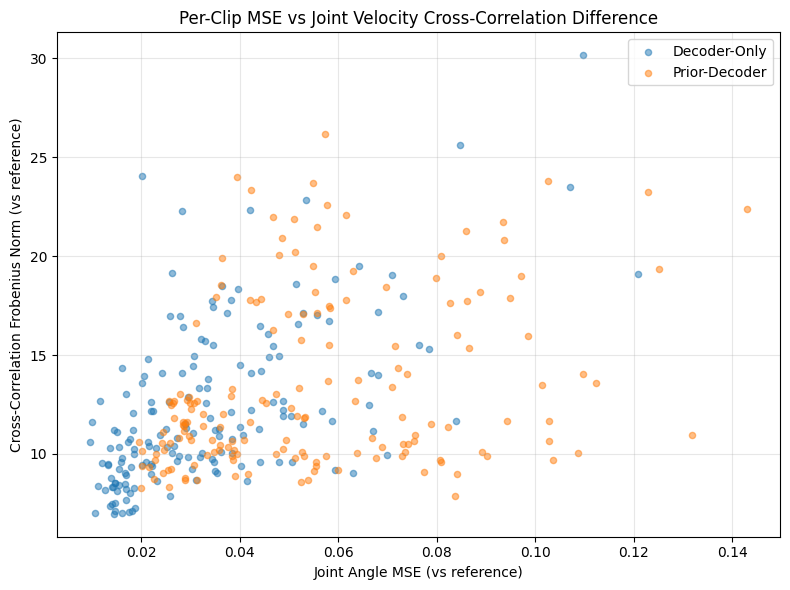

In [4]:
from scamper.analysis.utils import load_from_h5py

# ============ PATHS ============
DECODER_ONLY_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/decoder_only_123.h5"
)
PRIOR_DECODER_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123.h5"
)

# ============ LOAD ============
do_data = load_from_h5py(DECODER_ONLY_PATH)
pd_data = load_from_h5py(PRIOR_DECODER_PATH)

do_rollout = do_data["rollout_qpos"]
do_ref = do_data["reference_qpos"]
pd_rollout = pd_data["rollout_qpos"]
pd_ref = pd_data["reference_qpos"]

# ============ PER-CLIP JOINT-ANGLE MSE (qpos[7:]) ============
do_mse = np.mean((do_rollout[:, :, 7:] - do_ref[:, :, 7:]) ** 2, axis=(1, 2))
pd_mse = np.mean((pd_rollout[:, :, 7:] - pd_ref[:, :, 7:]) ** 2, axis=(1, 2))


# ============ PER-CLIP CROSS-CORRELATION FROBENIUS NORM ============
def per_clip_xcorr_frobenius(rollout_qpos, ref_qpos):
    """Frobenius norm of (rollout correlation - reference correlation) per clip."""
    roll_vel = np.diff(rollout_qpos[:, :, 7:], n=1, axis=1)  # (N, T-1, 67)
    ref_vel = np.diff(ref_qpos[:, :, 7:], n=1, axis=1)
    n_clips = roll_vel.shape[0]

    frob_norms = np.empty(n_clips)
    for i in range(n_clips):
        # Pearson correlation matrix across joints (67x67)
        roll_corr = np.corrcoef(roll_vel[i].T)  # (67, 67)
        ref_corr = np.corrcoef(ref_vel[i].T)  # (67, 67)
        diff = roll_corr - ref_corr
        frob_norms[i] = np.linalg.norm(diff, "fro")
    return frob_norms


do_frob = per_clip_xcorr_frobenius(do_rollout, do_ref)
pd_frob = per_clip_xcorr_frobenius(pd_rollout, pd_ref)

# ============ SUMMARY ============
print(f"{'Metric':<35} {'Decoder-Only':>22} {'Prior-Decoder':>22}")
print("-" * 80)
print(
    f"{'Joint MSE (mean +/- std)':<35} {do_mse.mean():.6f} +/- {do_mse.std():.6f}   {pd_mse.mean():.6f} +/- {pd_mse.std():.6f}"
)
print(
    f"{'XCorr Frob. norm (mean +/- std)':<35} {do_frob.mean():.4f} +/- {do_frob.std():.4f}       {pd_frob.mean():.4f} +/- {pd_frob.std():.4f}"
)

# ============ SCATTER PLOT ============
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(do_mse, do_frob, alpha=0.5, s=20, label="Decoder-Only")
ax.scatter(pd_mse, pd_frob, alpha=0.5, s=20, label="Prior-Decoder")
ax.set_xlabel("Joint Angle MSE (vs reference)")
ax.set_ylabel("Cross-Correlation Frobenius Norm (vs reference)")
ax.set_title("Per-Clip MSE vs Joint Velocity Cross-Correlation Difference")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Procrustes Distance in Joint-Angle PC Space

Fit PCA (3 components) on all reference clips concatenated, then project each
clip's reference and rollout joint-angle trajectories into that shared PC space.
Compute per-clip Procrustes distance (optimal rotation + scaling alignment)
between the reference and rollout 3D PC trajectories.

In [5]:
from scamper.analysis.utils import load_from_h5py
from sklearn.decomposition import PCA
from scipy.spatial import procrustes

# ============ PATHS ============
DECODER_ONLY_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/decoder_only_123.h5"
)
PRIOR_DECODER_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123.h5"
)

# ============ LOAD ============
do_data = load_from_h5py(DECODER_ONLY_PATH)
pd_data = load_from_h5py(PRIOR_DECODER_PATH)

do_rollout = do_data["rollout_qpos"]  # (N, T, 74)
do_ref = do_data["reference_qpos"]  # (N, T, 74)
pd_rollout = pd_data["rollout_qpos"]  # (N, T, 74)
pd_ref = pd_data["reference_qpos"]  # (N, T, 74)

n_clips, n_t, _ = do_ref.shape

# ============ FIT PCA ON ALL REFERENCE JOINT ANGLES ============
# Use reference from decoder_only (same as prior_decoder reference)
ref_joints = do_ref[:, :, 7:]  # (N, T, 67)
ref_joints_flat = ref_joints.reshape(-1, 67)  # (N*T, 67)

pca = PCA(n_components=3)
pca.fit(ref_joints_flat)

explained = pca.explained_variance_ratio_
print(
    f"PCA fit on all reference clips concatenated ({ref_joints_flat.shape[0]} frames)"
)
print(
    f"  Explained variance: PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, PC3={explained[2]:.1%}"
)
print(f"  Total: {sum(explained):.1%}")


# ============ PER-CLIP PROCRUSTES DISTANCE ============
def per_clip_procrustes(rollout_qpos, ref_qpos, pca_model):
    """Procrustes distance per clip in 3D PC space."""
    roll_joints = rollout_qpos[:, :, 7:]  # (N, T, 67)
    ref_joints = ref_qpos[:, :, 7:]
    n = roll_joints.shape[0]

    dists = np.empty(n)
    for i in range(n):
        ref_pc = pca_model.transform(ref_joints[i])  # (T, 3)
        roll_pc = pca_model.transform(roll_joints[i])  # (T, 3)
        _, _, disparity = procrustes(ref_pc, roll_pc)
        dists[i] = disparity
    return dists


do_proc = per_clip_procrustes(do_rollout, do_ref, pca)
pd_proc = per_clip_procrustes(pd_rollout, pd_ref, pca)

# ============ SUMMARY ============
print(f"\n{'Metric':<40} {'Decoder-Only':>22} {'Prior-Decoder':>22}")
print("-" * 86)
print(
    f"{'Procrustes dist (mean +/- std)':<40} {do_proc.mean():.6f} +/- {do_proc.std():.6f}   {pd_proc.mean():.6f} +/- {pd_proc.std():.6f}"
)

PCA fit on all reference clips concatenated (82320 frames)
  Explained variance: PC1=34.1%, PC2=14.3%, PC3=11.4%
  Total: 59.8%

Metric                                             Decoder-Only          Prior-Decoder
--------------------------------------------------------------------------------------
Procrustes dist (mean +/- std)           0.371584 +/- 0.205046   0.431832 +/- 0.210580


## State Occupancy KDE Heatmaps (PC Space)

Project every frame from reference, decoder-only, and prior-decoder rollouts
into the first two principal components (fitted on reference joint angles).
Apply 2D kernel density estimation and show three heatmaps side by side.

PCA fit on 82320 reference frames
  PC1=34.1%, PC2=14.3%, Total=48.4%
Computing KDEs...


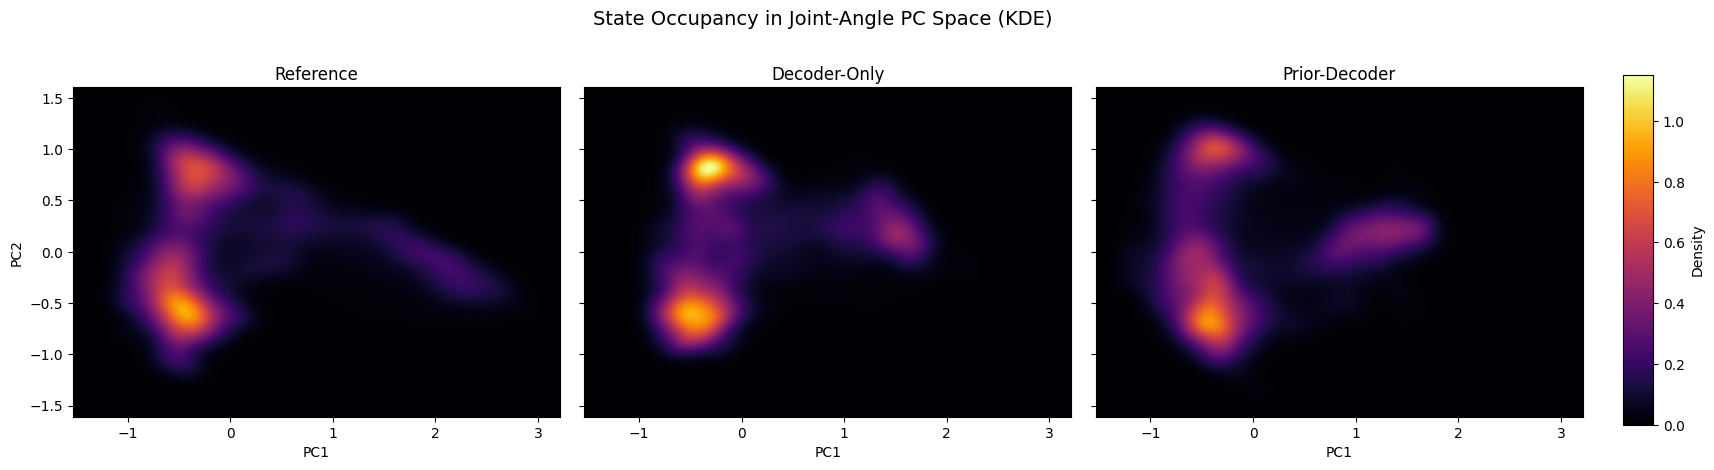


Frames per dataset: ref=82320, decoder-only=82320, prior-decoder=82320


In [2]:
from scamper.analysis.utils import load_from_h5py
from sklearn.decomposition import PCA
from scipy.stats import gaussian_kde

# ============ PATHS ============
DECODER_ONLY_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/decoder_only_123.h5"
)
PRIOR_DECODER_PATH = (
    "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123.h5"
)

# ============ LOAD ============
do_data = load_from_h5py(DECODER_ONLY_PATH)
pd_data = load_from_h5py(PRIOR_DECODER_PATH)

do_rollout = do_data["rollout_qpos"]  # (N, T, 74)
do_ref = do_data["reference_qpos"]  # (N, T, 74)
pd_rollout = pd_data["rollout_qpos"]  # (N, T, 74)
pd_ref = pd_data["reference_qpos"]  # (N, T, 74)

# ============ FIT PCA ON ALL REFERENCE JOINT ANGLES ============
ref_joints = do_ref[:, :, 7:]  # (N, T, 67)
ref_joints_flat = ref_joints.reshape(-1, 67)  # (N*T, 67)

pca = PCA(n_components=2)
pca.fit(ref_joints_flat)

explained = pca.explained_variance_ratio_
print(f"PCA fit on {ref_joints_flat.shape[0]} reference frames")
print(f"  PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, Total={sum(explained):.1%}")

# ============ PROJECT ALL FRAMES INTO PC SPACE ============
ref_pc = pca.transform(ref_joints_flat)  # (N*T, 2)
do_pc = pca.transform(do_rollout[:, :, 7:].reshape(-1, 67))  # (N*T, 2)
pd_pc = pca.transform(pd_rollout[:, :, 7:].reshape(-1, 67))  # (N*T, 2)

# ============ SHARED GRID FOR KDE EVALUATION ============
all_pc = np.vstack([ref_pc, do_pc, pd_pc])
margin = 0.05
x_min, x_max = all_pc[:, 0].min(), all_pc[:, 0].max()
y_min, y_max = all_pc[:, 1].min(), all_pc[:, 1].max()
x_range = x_max - x_min
y_range = y_max - y_min
x_min -= margin * x_range
x_max += margin * x_range
y_min -= margin * y_range
y_max += margin * y_range

grid_res = 200
xx, yy = np.mgrid[x_min : x_max : complex(grid_res), y_min : y_max : complex(grid_res)]
grid_points = np.vstack([xx.ravel(), yy.ravel()])

# ============ KDE FOR EACH DATASET ============
print("Computing KDEs...")
kde_ref = gaussian_kde(ref_pc.T)
kde_do = gaussian_kde(do_pc.T)
kde_pd = gaussian_kde(pd_pc.T)

z_ref = kde_ref(grid_points).reshape(xx.shape)
z_do = kde_do(grid_points).reshape(xx.shape)
z_pd = kde_pd(grid_points).reshape(xx.shape)

# ============ HEATMAPS ============
# Use shared colour scale across all three panels
vmax = max(z_ref.max(), z_do.max(), z_pd.max())

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 5),
    sharex=True,
    sharey=True,
    gridspec_kw={"wspace": 0.05, "right": 0.88},
)

titles = ["Reference", "Decoder-Only", "Prior-Decoder"]
densities = [z_ref, z_do, z_pd]

for ax, title, z in zip(axes, titles, densities):
    im = ax.pcolormesh(xx, yy, z, cmap="inferno", vmin=0, vmax=vmax, shading="gouraud")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_aspect("equal")

axes[0].set_ylabel("PC2")

# Place colorbar in its own axes to avoid overlap
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Density")

fig.suptitle("State Occupancy in Joint-Angle PC Space (KDE)", fontsize=14)
plt.show()

print(
    f"\nFrames per dataset: ref={ref_pc.shape[0]}, decoder-only={do_pc.shape[0]}, prior-decoder={pd_pc.shape[0]}"
)

In [3]:
from scipy.stats import wasserstein_distance_nd

N_SUBSAMPLE = 1000
rng_sub = np.random.default_rng(42)

ref_idx = rng_sub.choice(ref_pc.shape[0], N_SUBSAMPLE, replace=False)
do_idx = rng_sub.choice(do_pc.shape[0], N_SUBSAMPLE, replace=False)
pd_idx = rng_sub.choice(pd_pc.shape[0], N_SUBSAMPLE, replace=False)

w_do = wasserstein_distance_nd(ref_pc[ref_idx], do_pc[do_idx])
w_pd = wasserstein_distance_nd(ref_pc[ref_idx], pd_pc[pd_idx])

print(
    f"2D Wasserstein Distance in PC Space (vs Reference, {N_SUBSAMPLE} subsampled points):"
)
print(f"  Decoder-Only:  {w_do:.6f}")
print(f"  Prior-Decoder: {w_pd:.6f}")

2D Wasserstein Distance in PC Space (vs Reference, 1000 subsampled points):
  Decoder-Only:  0.169129
  Prior-Decoder: 0.216793


## State Occupancy KDE Heatmaps (Latent PC Space)

Same as the joint-angle KDE heatmaps above, but project the sampled latent
vectors (intention space) into their first two principal components.
PCA is fitted on reference latents only.

Decoder-only:  rollout_latents (168, 490, 16), ref_latents (168, 490, 16)
Prior-decoder: rollout_latents (168, 490, 16), ref_latents (168, 490, 16)
Latent dim: 16

PCA fit on 82320 reference latent frames
  PC1=13.9%, PC2=12.6%, Total=26.4%
Computing KDEs...


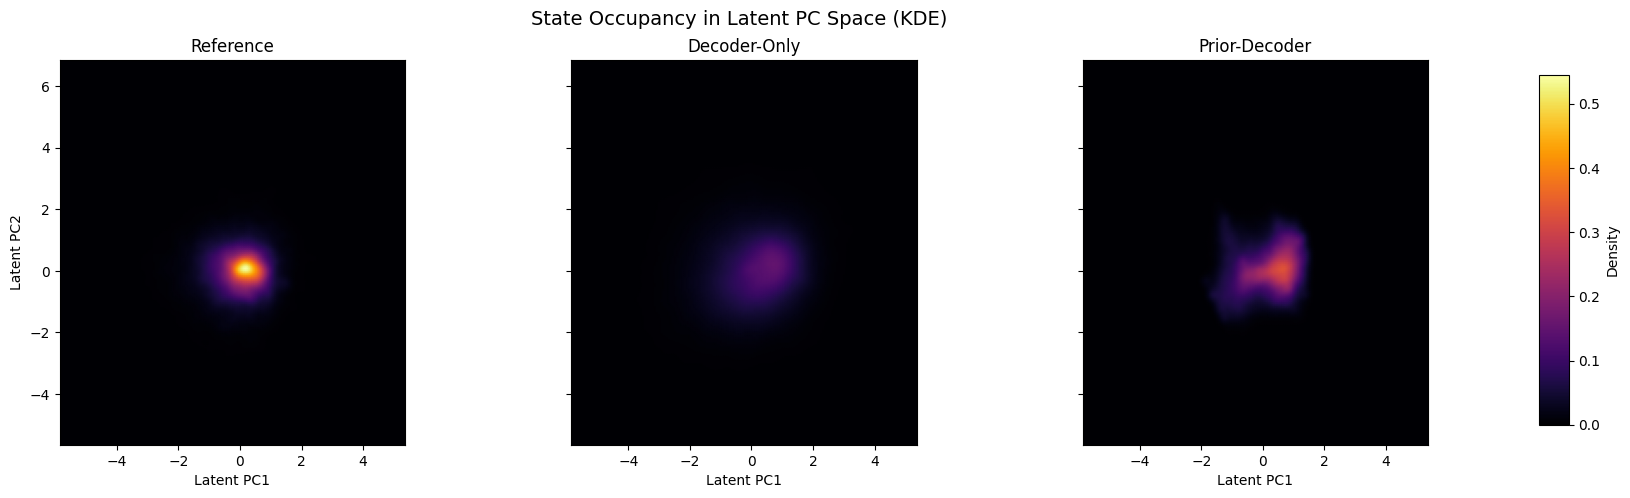


Frames per dataset: ref=82320, decoder-only=82320, prior-decoder=82320


In [11]:
from scamper.analysis.utils import load_from_h5py
from sklearn.decomposition import PCA
from scipy.stats import gaussian_kde

# ============ PATHS ============
DECODER_ONLY_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/decoder_only_123_latents.h5"
PRIOR_DECODER_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/data/follow_target_rollout/prior_decoder_123_latents.h5"

# ============ LOAD ============
do_data = load_from_h5py(DECODER_ONLY_PATH)
pd_data = load_from_h5py(PRIOR_DECODER_PATH)

do_rollout_lat = do_data["rollout_latents"]  # (N, T, latent_dim)
do_ref_lat = do_data["reference_latents"]  # (N, T, latent_dim)
pd_rollout_lat = pd_data["rollout_latents"]  # (N, T, latent_dim)
pd_ref_lat = pd_data["reference_latents"]  # (N, T, latent_dim)

latent_dim = do_ref_lat.shape[-1]
print(
    f"Decoder-only:  rollout_latents {do_rollout_lat.shape}, ref_latents {do_ref_lat.shape}"
)
print(
    f"Prior-decoder: rollout_latents {pd_rollout_lat.shape}, ref_latents {pd_ref_lat.shape}"
)
print(f"Latent dim: {latent_dim}")

# ============ FIT PCA ON ALL REFERENCE LATENTS ============
ref_lat_flat = do_ref_lat.reshape(-1, latent_dim)  # (N*T, latent_dim)

pca_lat = PCA(n_components=2)
pca_lat.fit(ref_lat_flat)

explained = pca_lat.explained_variance_ratio_
print(f"\nPCA fit on {ref_lat_flat.shape[0]} reference latent frames")
print(f"  PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, Total={sum(explained):.1%}")

# ============ PROJECT ALL FRAMES INTO LATENT PC SPACE ============
ref_lat_pc = pca_lat.transform(ref_lat_flat)  # (N*T, 2)
do_lat_pc = pca_lat.transform(do_rollout_lat.reshape(-1, latent_dim))  # (N*T, 2)
pd_lat_pc = pca_lat.transform(pd_rollout_lat.reshape(-1, latent_dim))  # (N*T, 2)

# ============ SHARED GRID FOR KDE EVALUATION ============
all_lat_pc = np.vstack([ref_lat_pc, do_lat_pc, pd_lat_pc])
margin = 0.05
x_min, x_max = all_lat_pc[:, 0].min(), all_lat_pc[:, 0].max()
y_min, y_max = all_lat_pc[:, 1].min(), all_lat_pc[:, 1].max()
x_range = x_max - x_min
y_range = y_max - y_min
x_min -= margin * x_range
x_max += margin * x_range
y_min -= margin * y_range
y_max += margin * y_range

grid_res = 200
xx, yy = np.mgrid[x_min : x_max : complex(grid_res), y_min : y_max : complex(grid_res)]
grid_points = np.vstack([xx.ravel(), yy.ravel()])

# ============ KDE FOR EACH DATASET ============
print("Computing KDEs...")
kde_ref = gaussian_kde(ref_lat_pc.T)
kde_do = gaussian_kde(do_lat_pc.T)
kde_pd = gaussian_kde(pd_lat_pc.T)

z_ref = kde_ref(grid_points).reshape(xx.shape)
z_do = kde_do(grid_points).reshape(xx.shape)
z_pd = kde_pd(grid_points).reshape(xx.shape)

# ============ HEATMAPS ============
vmax = max(z_ref.max(), z_do.max(), z_pd.max())

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 5),
    sharex=True,
    sharey=True,
    gridspec_kw={"wspace": 0.05, "right": 0.88},
)

titles = ["Reference", "Decoder-Only", "Prior-Decoder"]
densities = [z_ref, z_do, z_pd]

for ax, title, z in zip(axes, titles, densities):
    im = ax.pcolormesh(xx, yy, z, cmap="inferno", vmin=0, vmax=vmax, shading="gouraud")
    ax.set_title(title)
    ax.set_xlabel("Latent PC1")
    ax.set_aspect("equal")

axes[0].set_ylabel("Latent PC2")

cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(im, cax=cbar_ax, label="Density")

fig.suptitle("State Occupancy in Latent PC Space (KDE)", fontsize=14)
plt.show()

print(
    f"\nFrames per dataset: ref={ref_lat_pc.shape[0]}, decoder-only={do_lat_pc.shape[0]}, prior-decoder={pd_lat_pc.shape[0]}"
)

In [12]:
from scipy.stats import wasserstein_distance_nd

N_SUBSAMPLE = 1000
rng_sub = np.random.default_rng(42)

ref_idx = rng_sub.choice(ref_lat_pc.shape[0], N_SUBSAMPLE, replace=False)
do_idx = rng_sub.choice(do_lat_pc.shape[0], N_SUBSAMPLE, replace=False)
pd_idx = rng_sub.choice(pd_lat_pc.shape[0], N_SUBSAMPLE, replace=False)

w_do = wasserstein_distance_nd(ref_lat_pc[ref_idx], do_lat_pc[do_idx])
w_pd = wasserstein_distance_nd(ref_lat_pc[ref_idx], pd_lat_pc[pd_idx])

print(
    f"2D Wasserstein Distance in Latent PC Space (vs Reference, {N_SUBSAMPLE} subsampled points):"
)
print(f"  Decoder-Only:  {w_do:.6f}")
print(f"  Prior-Decoder: {w_pd:.6f}")

2D Wasserstein Distance in Latent PC Space (vs Reference, 1000 subsampled points):
  Decoder-Only:  0.585895
  Prior-Decoder: 0.221947


In [13]:
# L2 norm of latent vectors per frame, then average across all frames and clips
ref_l2 = np.linalg.norm(do_ref_lat, axis=-1).mean()
do_l2 = np.linalg.norm(do_rollout_lat, axis=-1).mean()
pd_l2 = np.linalg.norm(pd_rollout_lat, axis=-1).mean()

print(f"Average L2 Norm of Latent Vectors:")
print(f"  Reference:     {ref_l2:.6f}")
print(f"  Decoder-Only:  {do_l2:.6f}")
print(f"  Prior-Decoder: {pd_l2:.6f}")

Average L2 Norm of Latent Vectors:
  Reference:     1.974003
  Decoder-Only:  4.600315
  Prior-Decoder: 3.106369


Running 5000 latents through decoder (with zero mean proprio)...
  Last hidden layer size: 512
  Activation shapes: ref=(5000, 512), do=(5000, 512), pd=(5000, 512)


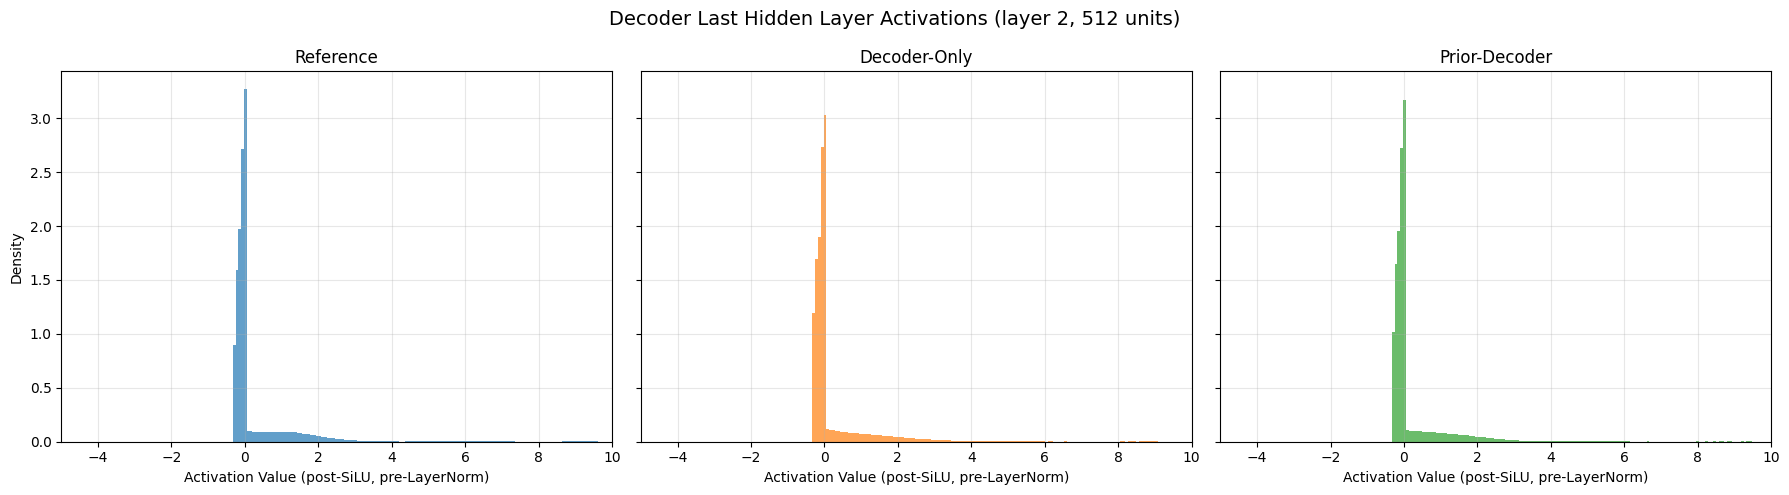

In [25]:
from scamper.agent.imitation import intention_network
from brax.training import distribution
from flax import linen as nn

# ============ BUILD DECODER MODULE ============
action_size = ckpt_cfg_dict["network_config"]["action_size"]
decoder_hidden_layer_sizes = tuple(
    ckpt_cfg_dict["network_config"]["decoder_layer_sizes"]
)
parametric_action_distribution = distribution.NormalTanhDistribution(
    event_size=action_size
)

layer_sizes = list(decoder_hidden_layer_sizes) + [
    parametric_action_distribution.param_size
]

decoder_module = intention_network.Decoder(layer_sizes=layer_sizes)

# Use zero normalized proprio (= mean proprioception) to isolate latent effect
zero_proprio = jnp.zeros(proprio_size)

# ============ SUBSAMPLE LATENTS ============
N_SAMPLES = 5000
rng_sub = np.random.default_rng(42)

ref_lat_all = do_ref_lat.reshape(-1, latent_dim)
do_lat_all = do_rollout_lat.reshape(-1, latent_dim)
pd_lat_all = pd_rollout_lat.reshape(-1, latent_dim)

ref_sample = ref_lat_all[rng_sub.choice(ref_lat_all.shape[0], N_SAMPLES, replace=False)]
do_sample = do_lat_all[rng_sub.choice(do_lat_all.shape[0], N_SAMPLES, replace=False)]
pd_sample = pd_lat_all[rng_sub.choice(pd_lat_all.shape[0], N_SAMPLES, replace=False)]


# ============ MANUAL FORWARD PASS: capture post-SiLU, pre-LayerNorm ============
def get_last_hidden_activations_pre_ln(latent_batch):
    """Run latents through decoder, return last hidden layer activations before LayerNorm."""
    batch_proprio = jnp.broadcast_to(
        zero_proprio, (latent_batch.shape[0], proprio_size)
    )
    x = jnp.concatenate([jnp.array(latent_batch), batch_proprio], axis=-1)

    params = decoder_params
    last_hidden_idx = len(decoder_hidden_layer_sizes) - 1

    for i, hidden_size in enumerate(layer_sizes):
        # Dense layer
        w = params[f"hidden_{i}"]["kernel"]
        b = params[f"hidden_{i}"]["bias"]
        x = x @ w + b

        if i != len(layer_sizes) - 1:  # hidden layers (not output)
            x = nn.silu(x)

            # Capture after SiLU, before LayerNorm
            if i == last_hidden_idx:
                pre_ln_activations = np.array(x)

            # LayerNorm (top-level in Flax compact params)
            ln_params = params[f"LayerNorm_{i}"]
            scale = ln_params["scale"]
            bias = ln_params.get("bias", jnp.zeros_like(scale))
            mean = x.mean(axis=-1, keepdims=True)
            var = x.var(axis=-1, keepdims=True)
            x = (x - mean) / jnp.sqrt(var + 1e-5) * scale + bias

    return pre_ln_activations


print(f"Running {N_SAMPLES} latents through decoder (with zero mean proprio)...")
ref_acts = get_last_hidden_activations_pre_ln(ref_sample)
do_acts = get_last_hidden_activations_pre_ln(do_sample)
pd_acts = get_last_hidden_activations_pre_ln(pd_sample)

print(f"  Last hidden layer size: {ref_acts.shape[-1]}")
print(
    f"  Activation shapes: ref={ref_acts.shape}, do={do_acts.shape}, pd={pd_acts.shape}"
)

# ============ HISTOGRAM (separate subplots) ============
bins = np.linspace(-5, 10, 200)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

titles = ["Reference", "Decoder-Only", "Prior-Decoder"]
data = [ref_acts, do_acts, pd_acts]
colors = ["tab:blue", "tab:orange", "tab:green"]

for ax, title, acts, color in zip(axes, titles, data, colors):
    ax.hist(acts.ravel(), bins=bins, alpha=0.7, density=True, color=color)
    ax.set_xlim(-5, 10)
    ax.set_xlabel("Activation Value (post-SiLU, pre-LayerNorm)")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Density")
fig.suptitle(
    f"Decoder Last Hidden Layer Activations (layer {len(decoder_hidden_layer_sizes) - 1}, {ref_acts.shape[-1]} units)",
    fontsize=14,
)
plt.tight_layout()
plt.show()

## 3D PCA of Single-Clip Latent Trajectory

Fit PCA (3 components) on a single reference clip's latent trajectory, then
project the corresponding decoder-only and prior-decoder rollout latent
trajectories into the same space. Time-colored line segments show the
temporal evolution of each trajectory.

In [32]:
from sklearn.decomposition import PCA
import plotly.graph_objects as go

# ============ SELECT CLIP ============
CLIP_IDX = 1  # Index into the test set (0 to N-1)

ref_clip = do_ref_lat[CLIP_IDX]  # (T, latent_dim)
do_clip = do_rollout_lat[CLIP_IDX]  # (T, latent_dim)
pd_clip = pd_rollout_lat[CLIP_IDX]  # (T, latent_dim)

T = ref_clip.shape[0]
print(f"Clip {CLIP_IDX}: {T} timesteps, latent_dim={ref_clip.shape[-1]}")

# ============ FIT PCA ON REFERENCE CLIP ============
pca3d = PCA(n_components=3)
ref_proj = pca3d.fit_transform(ref_clip)  # (T, 3)
do_proj = pca3d.transform(do_clip)  # (T, 3)
pd_proj = pca3d.transform(pd_clip)  # (T, 3)

explained = pca3d.explained_variance_ratio_
print(
    f"PCA explained variance: PC1={explained[0]:.1%}, PC2={explained[1]:.1%}, PC3={explained[2]:.1%} (total={sum(explained):.1%})"
)

# ============ INTERACTIVE 3D PLOT ============
fig = go.Figure()
timesteps = np.arange(T)

# --- Reference trajectory (viridis, colored by time) ---
fig.add_trace(
    go.Scatter3d(
        x=ref_proj[:, 0],
        y=ref_proj[:, 1],
        z=ref_proj[:, 2],
        mode="lines",
        line=dict(
            color=timesteps,
            colorscale="Viridis",
            width=4,
            colorbar=dict(title="Timestep", x=1.02, len=0.5),
        ),
        name="Reference",
        hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
        customdata=timesteps,
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[ref_proj[0, 0]],
        y=[ref_proj[0, 1]],
        z=[ref_proj[0, 2]],
        mode="markers",
        marker=dict(size=6, color="green", symbol="circle"),
        name="Reference start",
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter3d(
        x=[ref_proj[-1, 0]],
        y=[ref_proj[-1, 1]],
        z=[ref_proj[-1, 2]],
        mode="markers",
        marker=dict(size=6, color="red", symbol="x"),
        name="Reference end",
        showlegend=True,
    )
)

# --- Decoder-Only trajectory (Oranges, colored by time) ---
# fig.add_trace(
#     go.Scatter3d(
#         x=do_proj[:, 0], y=do_proj[:, 1], z=do_proj[:, 2],
#         mode="lines",
#         line=dict(color=timesteps, colorscale="Oranges", width=4),
#         name="Decoder-Only",
#         hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
#         customdata=timesteps,
#     )
# )
# fig.add_trace(
#     go.Scatter3d(
#         x=[do_proj[0, 0]], y=[do_proj[0, 1]], z=[do_proj[0, 2]],
#         mode="markers", marker=dict(size=6, color="orange", symbol="circle"),
#         name="Decoder-Only start", showlegend=True,
#     )
# )
# fig.add_trace(
#     go.Scatter3d(
#         x=[do_proj[-1, 0]], y=[do_proj[-1, 1]], z=[do_proj[-1, 2]],
#         mode="markers", marker=dict(size=6, color="darkred", symbol="x"),
#         name="Decoder-Only end", showlegend=True,
#     )
# )

# # --- Prior-Decoder trajectory (Blues, colored by time) ---
# fig.add_trace(
#     go.Scatter3d(
#         x=pd_proj[:, 0], y=pd_proj[:, 1], z=pd_proj[:, 2],
#         mode="lines",
#         line=dict(color=timesteps, colorscale="Blues", width=4),
#         name="Prior-Decoder",
#         hovertemplate="t=%{customdata}<br>PC1=%{x:.2f}<br>PC2=%{y:.2f}<br>PC3=%{z:.2f}",
#         customdata=timesteps,
#     )
# )
# fig.add_trace(
#     go.Scatter3d(
#         x=[pd_proj[0, 0]], y=[pd_proj[0, 1]], z=[pd_proj[0, 2]],
#         mode="markers", marker=dict(size=6, color="deepskyblue", symbol="circle"),
#         name="Prior-Decoder start", showlegend=True,
#     )
# )
# fig.add_trace(
#     go.Scatter3d(
#         x=[pd_proj[-1, 0]], y=[pd_proj[-1, 1]], z=[pd_proj[-1, 2]],
#         mode="markers", marker=dict(size=6, color="darkblue", symbol="x"),
#         name="Prior-Decoder end", showlegend=True,
#     )
# )

fig.update_layout(
    title=dict(
        text=f"Latent Trajectory in 3D PC Space (test clip {CLIP_IDX})",
        font=dict(size=13),
    ),
    scene=dict(
        xaxis_title="Latent PC1",
        yaxis_title="Latent PC2",
        zaxis_title="Latent PC3",
    ),
    width=850,
    height=700,
    legend=dict(x=0.01, y=0.99, font=dict(size=10)),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

Clip 1: 490 timesteps, latent_dim=16
PCA explained variance: PC1=17.1%, PC2=15.0%, PC3=12.6% (total=44.7%)


## UMAP Latent Manifold Visualization

Project subsampled latent vectors from all three datasets (reference,
decoder-only, prior-decoder) into 2D via UMAP, colored by source.
Downsampled to keep UMAP tractable.

In [40]:
import umap
import plotly.graph_objects as go

# ============ FLATTEN ALL LATENTS ============
ref_lat_all = do_ref_lat.reshape(-1, do_ref_lat.shape[-1])
do_lat_all = do_rollout_lat.reshape(-1, do_rollout_lat.shape[-1])
pd_lat_all = pd_rollout_lat.reshape(-1, pd_rollout_lat.shape[-1])

N_ref, N_do, N_pd = ref_lat_all.shape[0], do_lat_all.shape[0], pd_lat_all.shape[0]
print(
    f"Points per dataset: ref={N_ref}, decoder-only={N_do}, prior-decoder={N_pd} ({N_ref + N_do + N_pd} total)"
)

# ============ FIT 3D UMAP ON ALL THREE CONCATENATED ============
all_latents = np.vstack([ref_lat_all, do_lat_all, pd_lat_all])

print("Fitting 3D UMAP...")
reducer = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1)
embedding = reducer.fit_transform(all_latents)
print(f"  Embedding shape: {embedding.shape}")

# ============ INTERACTIVE 3D PLOT ============
ref_emb = embedding[:N_ref]
do_emb = embedding[N_ref : N_ref + N_do]
pd_emb = embedding[N_ref + N_do :]

fig = go.Figure()

fig.add_trace(
    go.Scatter3d(
        x=ref_emb[:, 0],
        y=ref_emb[:, 1],
        z=ref_emb[:, 2],
        mode="markers",
        marker=dict(size=1.5, color="rgba(0,0,255,0.4)"),
        name="Reference",
    )
)
fig.add_trace(
    go.Scatter3d(
        x=do_emb[:, 0],
        y=do_emb[:, 1],
        z=do_emb[:, 2],
        mode="markers",
        marker=dict(size=1.5, color="rgba(255,0,0,0.4)"),
        name="Decoder-Only",
    )
)
fig.add_trace(
    go.Scatter3d(
        x=pd_emb[:, 0],
        y=pd_emb[:, 1],
        z=pd_emb[:, 2],
        mode="markers",
        marker=dict(size=1.5, color="rgba(0,180,0,0.4)"),
        name="Prior-Decoder",
    )
)

fig.update_layout(
    title=dict(
        text=f"3D UMAP of Latent Vectors ({N_ref + N_do + N_pd} total points)",
        font=dict(size=14),
    ),
    scene=dict(
        xaxis_title="UMAP 1",
        yaxis_title="UMAP 2",
        zaxis_title="UMAP 3",
    ),
    width=850,
    height=700,
    legend=dict(
        x=0.01,
        y=0.99,
        font=dict(size=14),
        itemsizing="constant",
    ),
    margin=dict(l=0, r=0, t=60, b=0),
)
fig.show()

Points per dataset: ref=82320, decoder-only=82320, prior-decoder=82320 (246960 total)
Fitting 3D UMAP...
  Embedding shape: (246960, 3)
